# Entraînement d'un modèle 
On cherche à prédire la région selon le style de musique écouté

In [10]:
%pip install scikit-learn matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0 -> 26.2.2
[notice] To update, run: C:\Users\eleon\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (
    accuracy_score, f1_score, recall_score, classification_report,
    ConfusionMatrixDisplay, silhouette_score,
    adjusted_rand_score, normalized_mutual_info_score,
)

# Graine fixe : tout le groupe obtient les mêmes résultats
RANDOM_STATE = 42

Chargement du nouveau dataset nettoyé 

In [13]:
df = pd.read_csv("../Dataset/dataset_musique_region.csv")
print("Dimensions :", df.shape)

X = df.drop(columns="region")
y = df["region"]

repartition = pd.DataFrame({
    "Personnes": y.value_counts(),
    "Part (%)": (y.value_counts(normalize=True) * 100).round(1),
})
display(repartition)

Dimensions : (1986, 14)


,Personnes,Part (%)
region,,
Île-de-France,404,20.3
Auvergne-Rhône-Alpes,237,11.9
Grand Est,200,10.1
Nouvelle-Aquitaine,194,9.8
Hauts-de-France,188,9.5
Occitanie,161,8.1
Provence-Alpes-Côte d'Azur,129,6.5
Pays de la Loire,125,6.3
Bretagne,97,4.9


Split du dataset d'entraînement et de test

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("Entraînement :", X_train.shape)
print("Test :", X_test.shape)

Entraînement : (1588, 13)
Test : (398, 13)


Fonctions d'évaluation 

In [15]:
resultats = []

def scores(nom, y_vrai, y_pred):
    """Calcule les métriques et les ajoute au tableau de comparaison."""
    ligne = {
        "modele": nom,
        "accuracy": accuracy_score(y_vrai, y_pred),
        "f1_macro": f1_score(y_vrai, y_pred, average="macro", zero_division=0),
        "f1_pondere": f1_score(y_vrai, y_pred, average="weighted", zero_division=0),
        "recall_macro": recall_score(y_vrai, y_pred, average="macro", zero_division=0),
    }
    resultats.append(ligne)
    return ligne


def afficher_scores(ligne):
    """Affiche les métriques d'un modèle, arrondies à 3 décimales."""
    valeurs = pd.Series(ligne).drop("modele").astype(float).round(3)
    print(valeurs.to_string())


def evaluer(nom, modele):
    """Entraîne sur le train, prédit sur le test, affiche le détail par région."""
    modele.fit(X_train, y_train)
    y_pred = modele.predict(X_test)
    print(nom)
    afficher_scores(scores(nom, y_test, y_pred))
    print()
    print(classification_report(y_test, y_pred, zero_division=0))
    return modele, y_pred

### Baseline

In [16]:
baseline, pred_baseline = evaluer(
    "Baseline (région la plus fréquente)",
    DummyClassifier(strategy="most_frequent"),
)

Baseline (région la plus fréquente)
accuracy        0.204
f1_macro        0.028
f1_pondere      0.069
recall_macro    0.083

                            precision    recall  f1-score   support

      Auvergne-Rhône-Alpes       0.00      0.00      0.00        47
   Bourgogne-Franche-Comté       0.00      0.00      0.00        17
                  Bretagne       0.00      0.00      0.00        19
       Centre-Val de Loire       0.00      0.00      0.00        16
                 Grand Est       0.00      0.00      0.00        40
           Hauts-de-France       0.00      0.00      0.00        38
                 Normandie       0.00      0.00      0.00        18
        Nouvelle-Aquitaine       0.00      0.00      0.00        39
                 Occitanie       0.00      0.00      0.00        32
          Pays de la Loire       0.00      0.00      0.00        25
Provence-Alpes-Côte d'Azur       0.00      0.00      0.00        26
             Île-de-France       0.20      1.00      0.34 

### Modèle 1 : Régression logistique

In [17]:
reg_log, pred_reg_log = evaluer(
    "Régression logistique",
    LogisticRegression(max_iter=1000, class_weight="balanced"),
)

Régression logistique
accuracy        0.111
f1_macro        0.084
f1_pondere      0.113
recall_macro    0.101

                            precision    recall  f1-score   support

      Auvergne-Rhône-Alpes       0.15      0.13      0.14        47
   Bourgogne-Franche-Comté       0.07      0.35      0.11        17
                  Bretagne       0.11      0.11      0.11        19
       Centre-Val de Loire       0.00      0.00      0.00        16
                 Grand Est       0.27      0.07      0.12        40
           Hauts-de-France       0.04      0.05      0.05        38
                 Normandie       0.02      0.06      0.03        18
        Nouvelle-Aquitaine       0.07      0.03      0.04        39
                 Occitanie       0.00      0.00      0.00        32
          Pays de la Loire       0.03      0.04      0.04        25
Provence-Alpes-Côte d'Azur       0.10      0.15      0.12        26
             Île-de-France       0.35      0.22      0.27        81

   

### Modèle 2 : Random Forest

In [18]:
foret, pred_foret = evaluer(
    "Random Forest",
    RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
)

Random Forest
accuracy        0.113
f1_macro        0.106
f1_pondere      0.118
recall_macro    0.114

                            precision    recall  f1-score   support

      Auvergne-Rhône-Alpes       0.20      0.13      0.16        47
   Bourgogne-Franche-Comté       0.07      0.24      0.11        17
                  Bretagne       0.07      0.05      0.06        19
       Centre-Val de Loire       0.04      0.06      0.05        16
                 Grand Est       0.19      0.12      0.15        40
           Hauts-de-France       0.11      0.08      0.09        38
                 Normandie       0.05      0.17      0.07        18
        Nouvelle-Aquitaine       0.08      0.05      0.06        39
                 Occitanie       0.07      0.06      0.07        32
          Pays de la Loire       0.16      0.16      0.16        25
Provence-Alpes-Côte d'Azur       0.17      0.12      0.14        26
             Île-de-France       0.18      0.14      0.16        81

           

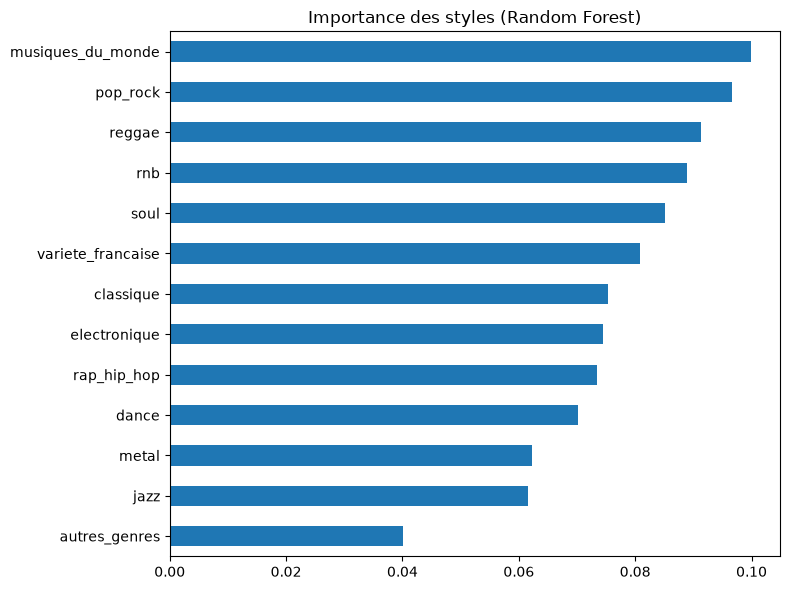

In [19]:
importances = pd.Series(foret.feature_importances_, index=X.columns).sort_values()
importances.plot(kind="barh", figsize=(8, 6), title="Importance des styles (Random Forest)")
plt.tight_layout()
plt.show()

### Matrices de confusion

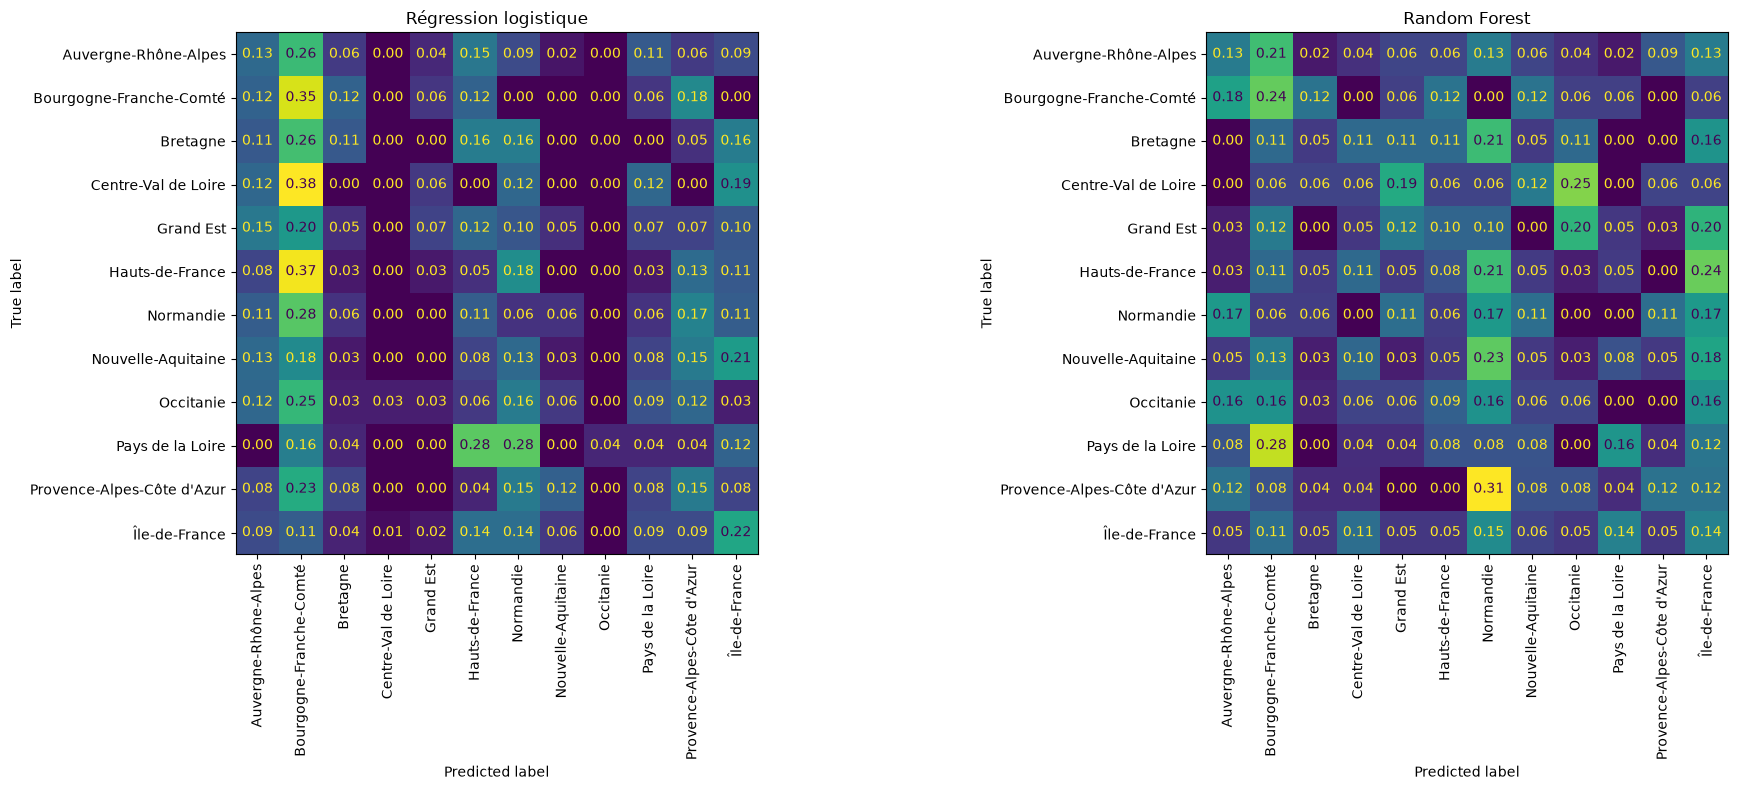

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

for ax, (nom, y_pred) in zip(axes, [
    ("Régression logistique", pred_reg_log),
    ("Random Forest", pred_foret),
]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, ax=ax, normalize="true",
        values_format=".2f", xticks_rotation=90, colorbar=False,
    )
    ax.set_title(nom)

plt.tight_layout()
plt.show()

## Modèle 3 : KMeans, choix du nombre de groupes

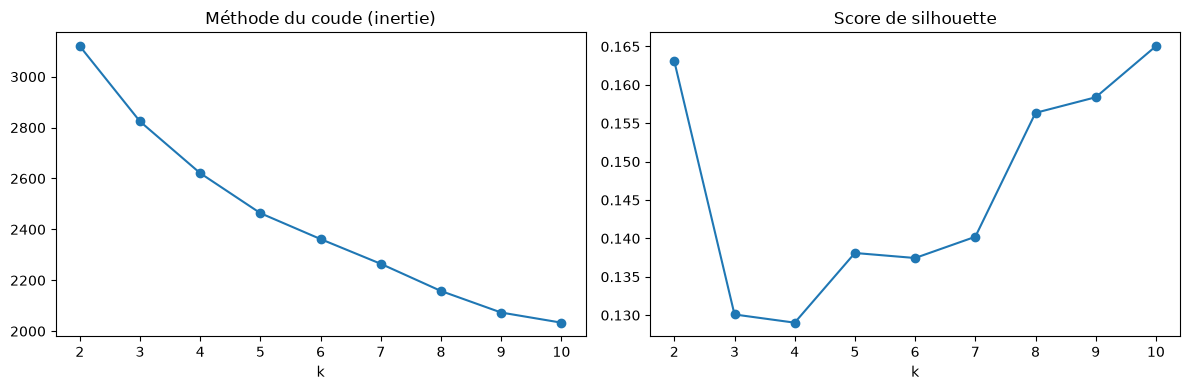

In [21]:
valeurs_k = range(2, 11)
inerties, silhouettes = [], []

for k in valeurs_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    etiquettes = km.fit_predict(X_train)
    inerties.append(km.inertia_)
    silhouettes.append(silhouette_score(X_train, etiquettes))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(valeurs_k), inerties, marker="o")
axes[0].set_title("Méthode du coude (inertie)")
axes[0].set_xlabel("k")
axes[1].plot(list(valeurs_k), silhouettes, marker="o")
axes[1].set_title("Score de silhouette")
axes[1].set_xlabel("k")
plt.tight_layout()
plt.show()

### Profils musicaux des groupes

In [22]:
K = 4  # à ajuster selon les courbes ci-dessus

kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE)
clusters_train = kmeans.fit_predict(X_train)

profils = X_train.assign(cluster=clusters_train).groupby("cluster").mean().round(2)
profils["effectif"] = pd.Series(clusters_train).value_counts().sort_index()
display(profils)

,variete_francaise,pop_rock,rap_hip_hop,classique,jazz,dance,electronique,metal,rnb,soul,reggae,musiques_du_monde,autres_genres,effectif
cluster,,,,,,,,,,,,,,
0,0.53,0.00,0.16,0.23,0.09,0.16,0.09,0.07,0.09,0.06,0.07,0.20,0.09,476
1,0.55,0.59,0.85,0.07,0.09,0.48,0.28,0.09,0.94,0.33,0.36,0.27,0.05,322
2,0.76,0.73,0.14,0.80,0.73,0.31,0.24,0.19,0.23,0.46,0.40,0.65,0.05,283
3,0.65,1.00,0.09,0.11,0.08,0.18,0.12,0.13,0.10,0.08,0.09,0.11,0.06,507


### Groupes musicaux × régions

In [23]:
croisement = pd.crosstab(
    pd.Series(clusters_train, name="cluster"),
    pd.Series(y_train.values, name="region"),
    normalize="index",
).round(2)
display(croisement)

clusters_test = kmeans.predict(X_test)
print("ARI :", round(adjusted_rand_score(y_test, clusters_test), 3))
print("NMI :", round(normalized_mutual_info_score(y_test, clusters_test), 3))

region,Auvergne-Rhône-Alpes,Bourgogne-Franche-Comté,Bretagne,Centre-Val de Loire,Grand Est,Hauts-de-France,Normandie,Nouvelle-Aquitaine,Occitanie,Pays de la Loire,Provence-Alpes-Côte d'Azur,Île-de-France
cluster,,,,,,,,,,,,
0,0.11,0.05,0.06,0.04,0.11,0.11,0.04,0.09,0.08,0.04,0.07,0.20
1,0.11,0.05,0.05,0.06,0.10,0.08,0.05,0.08,0.08,0.09,0.05,0.20
2,0.11,0.02,0.05,0.03,0.08,0.07,0.03,0.11,0.10,0.06,0.09,0.25
3,0.14,0.05,0.04,0.03,0.11,0.10,0.06,0.10,0.07,0.07,0.05,0.18


ARI : 0.006
NMI : 0.03


### KMeans utilisé comme classifieur

In [24]:
region_par_cluster = (
    pd.Series(y_train.values)
    .groupby(clusters_train)
    .agg(lambda s: s.mode()[0])
)
print("Région attribuée à chaque groupe :")
display(region_par_cluster)

pred_kmeans = region_par_cluster.reindex(clusters_test).values
print(f"KMeans (k={K})")
afficher_scores(scores(f"KMeans (k={K})", y_test, pred_kmeans))

Région attribuée à chaque groupe :


0    Île-de-France
1    Île-de-France
2    Île-de-France
3    Île-de-France
dtype: object

KMeans (k=4)
accuracy        0.204
f1_macro        0.028
f1_pondere      0.069
recall_macro    0.083


# Conclusion : comparaison des modèles

,accuracy,f1_macro,f1_pondere,recall_macro
modele,,,,
Baseline (région la plus fréquente),0.204,0.028,0.069,0.083
Régression logistique,0.111,0.084,0.113,0.101
Random Forest,0.113,0.106,0.118,0.114
KMeans (k=4),0.204,0.028,0.069,0.083


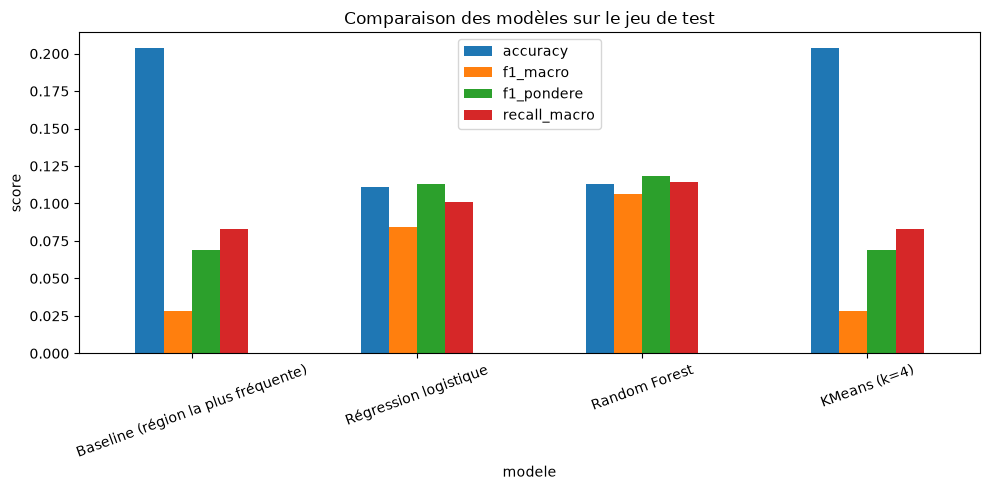

In [25]:
comparaison = pd.DataFrame(resultats).drop_duplicates("modele", keep="last").set_index("modele").round(3)
display(comparaison)

comparaison.plot(kind="bar", figsize=(10, 5), rot=20, title="Comparaison des modèles sur le jeu de test")
plt.ylabel("score")
plt.tight_layout()
plt.show()